In [88]:
import numpy as np

PDF_X = np.linspace(0, 100, 1000)
trapezoid = np.trapz

In [89]:
def k(D, mean_gw, sigma_gw, mean_cand, sigma_cand):
    return (D*sigma_cand - mean_gw*sigma_cand)**2 + (D*sigma_gw - mean_cand*sigma_gw)**2

def integrand(D, mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos):
    sigma_cand = sigma_cand_eff(D, sigma_cand_neg, sigma_cand_pos, mean_cand)
    _k = k(D, mean_gw, sigma_gw, mean_cand, sigma_cand)
    return np.exp(-_k/(sigma_gw*sigma_cand)**2)

def sigma_cand_eff(D, sigma_cand_neg, sigma_cand_pos, mean_cand):

    if not isinstance(D, np.ndarray):    
        if D > mean_cand:
            return sigma_cand_pos
        return sigma_cand_neg

    return np.where(
        D <= mean_cand,
        sigma_cand_neg,
        sigma_cand_pos
    )

def prefactor(sigma_gw, sigma_cand_neg, sigma_cand_pos):
    return 1/np.sqrt(np.pi*sigma_gw*(sigma_cand_neg+sigma_cand_pos))

@np.vectorize(excluded=['sigma_gw', 'sigma_cand_neg', 'sigma_cand_pos'])
def bc(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos, x=PDF_X):
    _i = lambda x : integrand(x, mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos)
    _p = prefactor(sigma_gw, sigma_cand_neg, sigma_cand_pos)
    return _p*trapezoid(_i(x), x=x)

In [90]:
bc(50, 10, 70, 50, 1e-3)

array(0.37495946)

(0.0, 1.0)

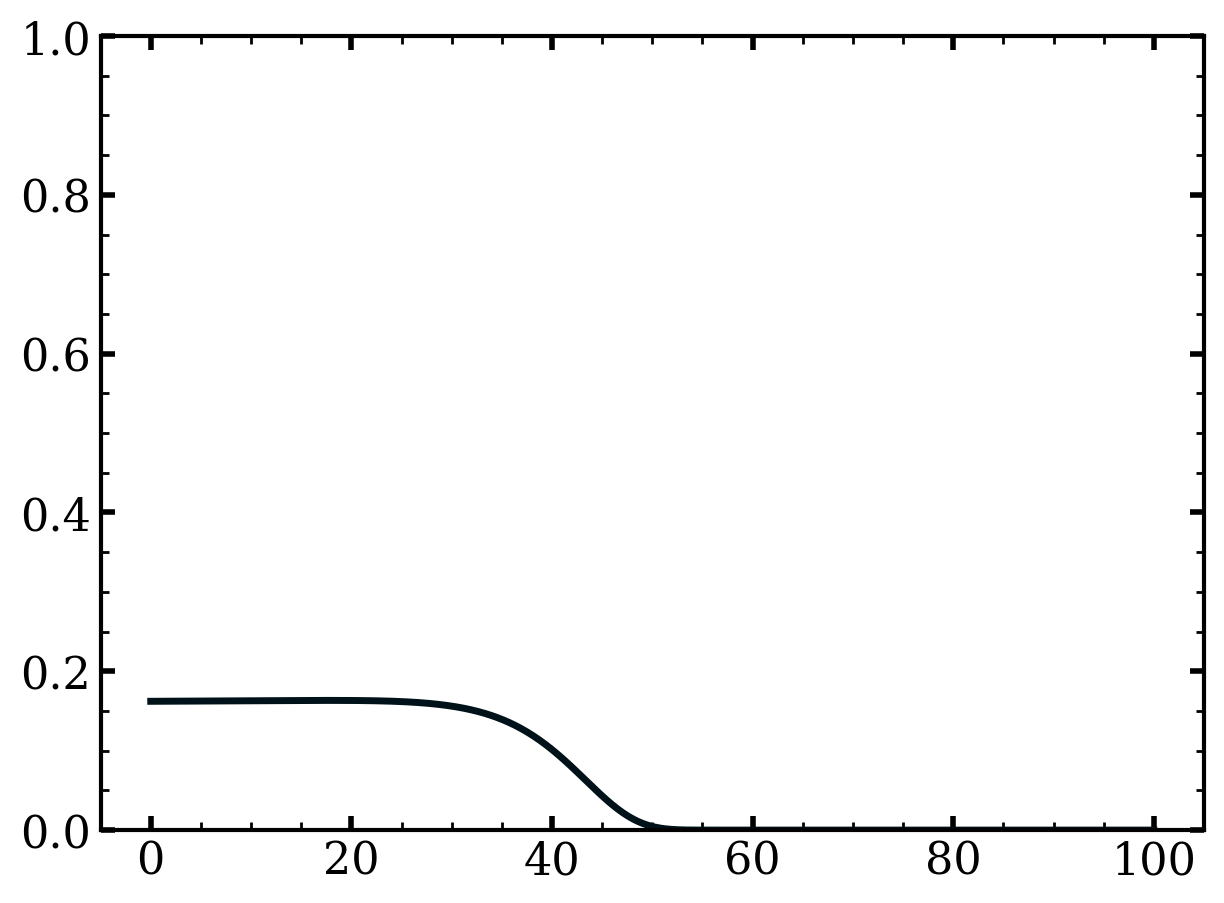

In [91]:
dist = PDF_X #np.linspace(0, 3, 1_000)

import matplotlib.pyplot as plt
plt.plot(dist, bc(x, 50, 10, 20, 1e-3))
plt.ylim(0,1)

In [72]:
bc(x, 50, 10, 20, 1e-3)

0.015884496924518984